# Dataset over de tijd: opschonen en samenvoegen

Voegt de twee bronnen samen tot één tabel waarin elke rij een auto **op een bepaald moment** is:

| Bron | Periode | Inhoud |
|---|---|---|
| `wayback_cars.csv` | mrt 2023 – dec 2025 | pagina 1 van de zoekresultaten per model per maand |
| `cars.csv` | okt 2026 | het volledige aanbod |

Uitvoer: `dataset_tijd.parquet`. De bronbestanden worden niet aangepast.

Keuzes:
- **Alleen NL** en van Wayback alleen `page_sort == "standard"` (vóór 2023 vooral Duitse auto's en een andere sortering).
- **Bouwjaar 2005 of later**, zoals in `cars.csv`.
- **Leeftijd in jaren met decimalen**: alleen het bouwjaar is bekend, dus we nemen aan dat elke auto midden in
  het jaar is geregistreerd. Met hele jaren wordt elke auto op 1 januari in één keer een jaar ouder,
  wat een nep-sprong in de prijzen geeft.
- **Nieuwprijs voor Wayback**: de mediaan van de exacte nieuwprijzen in `cars.csv` voor hetzelfde merk + model + bouwjaar.
- **Duplicaten blijven staan.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SCRAPE_DATUM_2026 = "2026-10-05"   # einde van de cars.csv-scrape (zelfde als marktindex.ipynb)
WAYBACK_VANAF = "2023-03-01"       # daarvoor vrijwel geen NL-auto's
MIN_BOUWJAAR = 2005
MAX_KM = 1_000_000
MAX_PRIJS_T_O_V_NIEUW = 1.5        # prijs > 1,5 × nieuwprijs: placeholder of verzamelobject
MAX_PRIJS_ZONDER_NIEUW = 500_000   # grens voor auto's zonder nieuwprijs

EXACTE_BRONNEN = ["autoscout", "rdw_kenteken"]

## 1. Inladen

In [2]:
scrape = pd.read_csv("../webscrape/data/cars.csv")
wayback = pd.read_csv("../webscrape/data/wayback_cars.csv")
cpi = pd.read_csv("cpi.csv", index_col="year")

print("cars.csv:        ", scrape.shape)
print("wayback_cars.csv:", wayback.shape)

cars.csv:         (148662, 10)
wayback_cars.csv: (140650, 13)


## 2. Wayback filteren

Telt per stap hoeveel rijen er afvallen, zodat je dat in je verslag kunt noemen.

In [3]:
wb = wayback.copy()
wb["snapshot_date"] = pd.to_datetime(wb["snapshot_date"])

stappen = [("start", len(wb))]
wb = wb[wb["country"] == "NL"];                      stappen.append(("land = NL", len(wb)))
wb = wb[wb["page_sort"] == "standard"];              stappen.append(("sortering = standard", len(wb)))
wb = wb[wb["snapshot_date"] >= WAYBACK_VANAF];       stappen.append((f"vanaf {WAYBACK_VANAF}", len(wb)))

pd.DataFrame(stappen, columns=["stap", "rijen over"])

,stap,rijen over
0,start,140650
1,land = NL,130430
2,sortering = standard,130430
3,vanaf 2023-03-01,130430


## 3. Nieuwprijs voor Wayback

Wayback heeft vrijwel nooit een nieuwprijs. We nemen de mediaan van de **exacte** nieuwprijzen
(`autoscout` of `rdw_kenteken`) in `cars.csv`:
1. hetzelfde merk + model + bouwjaar → `schatting_cars_model_jaar`;
2. anders hetzelfde merk + model (alle bouwjaren) → `schatting_cars_model`.

In [4]:
exact = scrape[scrape["new_price_source"].isin(EXACTE_BRONNEN)]
per_model_jaar = exact.groupby(["brand", "model", "year"])["new_price_eur"].median()
per_model = exact.groupby(["brand", "model"])["new_price_eur"].median()

wb["year"] = wb["year"].astype("Int64")
sleutel_mj = pd.MultiIndex.from_frame(wb[["brand", "model", "year"]])
sleutel_m = pd.MultiIndex.from_frame(wb[["brand", "model"]])

prijs_mj = pd.Series(per_model_jaar.reindex(sleutel_mj).values, index=wb.index)
prijs_m = pd.Series(per_model.reindex(sleutel_m).values, index=wb.index)

bron = pd.Series(pd.NA, index=wb.index, dtype="object")
bron[prijs_m.notna()] = "schatting_cars_model"
bron[prijs_mj.notna()] = "schatting_cars_model_jaar"
bron[wb["new_price_eur"].notna()] = "autoscout"   # de enkele keer dat Wayback zelf een nieuwprijs heeft
wb["new_price_source"] = bron
wb["new_price_eur"] = wb["new_price_eur"].fillna(prijs_mj).fillna(prijs_m)

wb["new_price_source"].value_counts(dropna=False)

new_price_source
schatting_cars_model_jaar    112400
schatting_cars_model          15930
<NA>                           2100
Name: count, dtype: int64

## 4. Samenvoegen

In [5]:
scrape_t = scrape.assign(bron="scrape_2026", snapshot_date=pd.Timestamp(SCRAPE_DATUM_2026))
wb_t = wb.assign(bron="wayback")

KOLOMMEN = ["bron", "snapshot_date", "brand", "model", "year", "mileage_km", "fuel_type", "transmission",
            "body_type", "price_eur", "new_price_eur", "new_price_source"]
d = pd.concat([wb_t[KOLOMMEN], scrape_t[KOLOMMEN]], ignore_index=True)

d["maand"] = d["snapshot_date"].dt.to_period("M").astype(str)
d["brand_model"] = d["brand"] + " " + d["model"]
d.groupby("bron").size()

bron
scrape_2026    148662
wayback        130430
dtype: int64

## 5. Opschonen (beide bronnen)

Alleen regels, geen indexnummers, zodat het ook na een nieuwe scrape klopt.

In [6]:
stappen = [("start", len(d))]

d = d.dropna(subset=["model", "year", "mileage_km", "price_eur"])
stappen.append(("geen ontbrekend model/bouwjaar/km/prijs", len(d)))

d = d[d["year"] >= MIN_BOUWJAAR]
stappen.append((f"bouwjaar >= {MIN_BOUWJAAR}", len(d)))

d = d[d["year"] <= d["snapshot_date"].dt.year]
stappen.append(("bouwjaar niet na waarnemingsjaar", len(d)))

d = d[d["mileage_km"] < MAX_KM]
stappen.append((f"km < {MAX_KM:,}", len(d)))

met_nieuw = d["new_price_eur"].notna()
te_duur = (met_nieuw & (d["price_eur"] > MAX_PRIJS_T_O_V_NIEUW * d["new_price_eur"])) | \
          (~met_nieuw & (d["price_eur"] > MAX_PRIJS_ZONDER_NIEUW))
d = d[~te_duur]
stappen.append((f"prijs <= {MAX_PRIJS_T_O_V_NIEUW} × nieuwprijs (of <= €{MAX_PRIJS_ZONDER_NIEUW:,})", len(d)))

d = d.reset_index(drop=True)
d["year"] = d["year"].astype(int)
d["mileage_km"] = d["mileage_km"].astype(int)

pd.DataFrame(stappen, columns=["stap", "rijen over"])

,stap,rijen over
0,start,279092
1,geen ontbrekend model/bouwjaar/km/prijs,278525
2,bouwjaar >= 2005,268987
3,bouwjaar niet na waarnemingsjaar,268939
4,"km < 1,000,000",268922
5,"prijs <= 1.5 × nieuwprijs (of <= €500,000)",268369


## 6. Afgeleide kolommen

- `age`: leeftijd in jaren met decimalen op het moment van de waarneming
  (`waarnemingsmoment − (bouwjaar + 0,5)`).
- `new_price_obs`: nieuwprijs omgerekend naar het prijsniveau van het **waarnemingsjaar** met de algemene CPI (CBS).
  Een catalogusprijs uit 2010 is in euro's van 2010; de vraagprijs in 2024 is in euro's van 2024.
- `restwaarde`: `price_eur / new_price_obs`.

In [7]:
moment = d["snapshot_date"].dt.year + (d["snapshot_date"].dt.month - 0.5) / 12
d["age"] = (moment - (d["year"] + 0.5)).clip(lower=0).round(3)

obs_jaar = d["snapshot_date"].dt.year
inflatie = obs_jaar.map(cpi["cpi_all"]) / d["year"].map(cpi["cpi_all"])
d["new_price_obs"] = (d["new_price_eur"] * inflatie).round()
d["restwaarde"] = (d["price_eur"] / d["new_price_obs"]).round(4)

d[["bron", "snapshot_date", "brand_model", "year", "age", "mileage_km", "price_eur",
   "new_price_eur", "new_price_obs", "restwaarde"]].sample(5, random_state=1)

,bron,snapshot_date,brand_model,year,age,mileage_km,price_eur,new_price_eur,new_price_obs,restwaarde
164627,scrape_2026,2026-10-05,Mercedes-Benz Vito,2019,7.292,196944,10400,65557.0,86726.0,0.1199
184699,scrape_2026,2026-10-05,Volkswagen Golf,2017,9.292,176214,11000,31509.0,43513.0,0.2528
232711,scrape_2026,2026-10-05,Ford Focus,2020,6.292,65290,13995,28295.0,36963.0,0.3786
123117,scrape_2026,2026-10-05,Audi A3,2014,12.292,127000,11000,39107.0,55256.0,0.1991
115833,wayback,2025-04-21,Mercedes-Benz GLK 200,2011,13.792,94081,14995,51587.5,74014.0,0.2026


## 7. Controles

In [8]:
print("Rijen per bron:")
print(d["bron"].value_counts().to_string(), "\n")

print("Ontbrekend (aandeel):")
print(d.isna().mean().round(3)[lambda s: s > 0].to_string(), "\n")

print("Nieuwprijs-bron:")
print(d["new_price_source"].value_counts(dropna=False).to_string())

Rijen per bron:
bron
scrape_2026    148077
wayback        120292 

Ontbrekend (aandeel):
body_type           0.446
new_price_eur       0.002
new_price_source    0.002
new_price_obs       0.002
restwaarde          0.002 

Nieuwprijs-bron:
new_price_source
schatting_cars_model_jaar    111947
autoscout                     74245
rdw_kenteken                  38868
schatting                     34910
schatting_cars_model           7954
<NA>                            391
NaN                              54


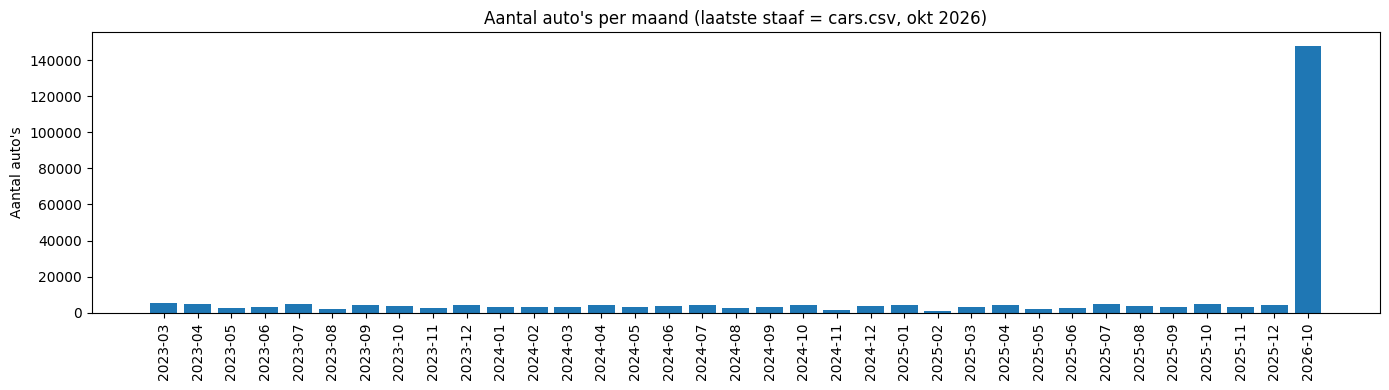

In [9]:
per_maand = d.groupby("maand").size()

plt.figure(figsize=(14, 4))
plt.bar(per_maand.index, per_maand.values)
plt.xticks(rotation=90)
plt.ylabel("Aantal auto's")
plt.title("Aantal auto's per maand (laatste staaf = cars.csv, okt 2026)")
plt.tight_layout()
plt.show()

Vergelijking van de bronnen. Wayback (pagina 1) bevat gemiddeld oudere auto's met meer kilometers dan het
volledige aanbod van 2026. Dat verschil is geen marktontwikkeling: geef `bron` daarom mee aan het model.

In [10]:
d.assign(jaar=d["snapshot_date"].dt.year).groupby("jaar").agg(
    auto_s=("price_eur", "size"),
    mediaan_prijs=("price_eur", "median"),
    mediaan_leeftijd=("age", "median"),
    mediaan_km=("mileage_km", "median"),
    mediaan_restwaarde=("restwaarde", "median"),
).round(2)

,auto_s,mediaan_prijs,mediaan_leeftijd,mediaan_km,mediaan_restwaarde
jaar,,,,,
2023,38176,25500.0,6.04,91069.0,0.40
2024,40416,22335.0,6.79,102000.5,0.35
2025,41700,22950.0,7.29,106107.5,0.32
2026,148077,22945.0,5.29,86619.0,0.41


## 8. Opslaan

In [11]:
VOLGORDE = ["bron", "snapshot_date", "maand", "brand", "model", "brand_model", "year", "age", "mileage_km",
            "fuel_type", "transmission", "body_type", "price_eur", "new_price_eur", "new_price_source",
            "new_price_obs", "restwaarde"]
d[VOLGORDE].to_parquet("dataset_tijd.parquet", index=False)
print(f"{len(d)} rijen opgeslagen in dataset_tijd.parquet")

268369 rijen opgeslagen in dataset_tijd.parquet


## Kolommen in `dataset_tijd.parquet`

| Kolom | Betekenis |
|---|---|
| `bron` | `wayback` of `scrape_2026`: geef mee aan het model (bronverschil) |
| `snapshot_date`, `maand` | moment van de waarneming; split hierop voor de backtest |
| `brand`, `model`, `brand_model` | merk en model |
| `year`, `age` | bouwjaar en leeftijd (jaren, met decimalen) op het moment van de waarneming |
| `mileage_km`, `fuel_type`, `transmission` | kenmerken |
| `body_type` | **alleen gevuld voor `scrape_2026`**: niet als feature gebruiken over beide bronnen |
| `price_eur` | vraagprijs (nominaal) |
| `new_price_eur` | nieuwprijs in euro's van het bouwjaar; `new_price_source` zegt hoe hij gevonden is |
| `new_price_obs` | nieuwprijs in euro's van het waarnemingsjaar |
| `restwaarde` | `price_eur / new_price_obs` |

**Beperkingen:** leeftijd is benaderd (geen registratiemaand), Wayback is pagina 1 en niet het hele aanbod,
en er is geen data van januari tot september 2026.